# CMP6202 – Notebook 02: Splitting and exploratory data analysis

Evidence for report sections **2.2–2.4**. Splits the 75,000-flow sample once, checks the split for leakage, then
explores the **training set only**.

EDA questions:
* **Q1:** how severe is the class imbalance once duplicates are removed? (metrics, resampling)
* **Q2:** which flow statistics separate attacks from benign traffic without port or time? (features, shortcuts)
* **Q3:** how skewed, outlier-prone and redundant are the features? (transforms, scaling, feature selection)

In [1]:
# Google Colab setup. On a local machine this cell does nothing.
# On Colab: upload the project folder to Google Drive (README, "Run on Google Colab"). The cell mounts Drive,
# finds the folder, installs the pinned libraries and makes `nids` importable.
import os
import subprocess
import sys

if "google.colab" in sys.modules:
    from importlib.metadata import version

    from google.colab import drive

    drive.mount("/content/drive")
    # I accept both upload locations the README describes and pick the one that holds the nids package.
    candidates = ["/content/drive/MyDrive/CMP6202_NIDS/Project", "/content/drive/MyDrive/Project"]
    found = [path for path in candidates if os.path.isdir(os.path.join(path, "src", "nids"))]
    if not found:
        raise SystemExit(f"Project folder not found on Drive; looked in {candidates}")
    PROJECT_DIR = found[0]
    os.chdir(PROJECT_DIR)
    loaded = {name: version(dist) for name, dist in (("numpy", "numpy"), ("pandas", "pandas"), ("sklearn", "scikit-learn"))
              if name in sys.modules}
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements-colab.txt"], check=True)
    sys.path.insert(0, os.path.join(PROJECT_DIR, "src"))
    changed = [name for name, old in loaded.items()
               if old != version({"sklearn": "scikit-learn"}.get(name, name))]
    if changed:
        # A library that was already imported cannot be replaced in a running session.
        raise SystemExit(f"Upgraded {changed}: choose Runtime > Restart session, then run this cell again.")
    print("Running on Colab from", PROJECT_DIR)
else:
    print("Running locally; Colab setup skipped")

Running locally; Colab setup skipped


## **Import the libraries and load the sample**

In [2]:
import json

import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.model_selection import train_test_split

from nids import config, data, eda, features, plotting, report_numbers  # my package: src/nids

plotting.apply_style()
for folder in (config.FIGURES_DIR, config.TABLES_DIR):
    folder.mkdir(parents=True, exist_ok=True)

sample = data.load_sample()
manifest = json.loads(config.MANIFEST_JSON.read_text())
assert manifest["sample_sha256"] == data.sha256_of(config.SAMPLE_PARQUET), "sample differs from notebook 01"
sample.shape

(75000, 80)

# 2 Exploratory Data Analysis
## 2.2 Splitting the dataset

One 80/20 split, stratified by `Label` (only 46 FTP flows exist), seed 42, made before any exploration
(`train_test_split`, Weeks 4–5 labs).

In [3]:
X = sample.drop(columns=config.LABEL_COL)
y = sample[config.LABEL_COL]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=config.TEST_SIZE, stratify=y, random_state=config.SEED)

# data.split_sample wraps the same call; I check both give the same rows before saving the split.
split = data.split_sample(sample)
assert X_train.index.equals(split.X_train.index) and X_test.index.equals(split.X_test.index)
data.save_split(split)
print(f"Train {X_train.shape}, test {X_test.shape}")

Train (60000, 79), test (15000, 79)


In [4]:
# Duplicates were removed before splitting, so no feature vector may occur in both partitions.
leakage = data.assert_no_leakage(split)
partition_counts = pd.DataFrame({"train": y_train.value_counts(), "test": y_test.value_counts()}
                                ).reindex(plotting.CLASS_ORDER)
for part in ("train", "test"):
    partition_counts[f"{part} %"] = partition_counts[part] / partition_counts[part].sum() * 100
partition_counts.loc["Total"] = partition_counts.sum()
partition_counts.round(2).to_csv(config.TABLES_DIR / "2_2_split_counts.csv")
print("Leakage check:", leakage)
partition_counts.round(2)

Leakage check: {'train_rows': 60000, 'test_rows': 15000, 'unique_train_vectors': 60000, 'unique_test_vectors': 15000, 'shared_vectors': 0}


,train,test,train %,test %
Label,,,,
Benign,50857,12715,84.76,84.77
FTP-BruteForce,37,9,0.06,0.06
SSH-Bruteforce,9106,2276,15.18,15.17
Total,60000,15000,100.00,100.00


The preprocessing that learns from data sits in one pipeline, refitted on every training fold: one-hot `Protocol`,
drop constant columns, standardise. Here I fit it on the training set only to see the resulting feature space.

In [5]:
preprocessor = features.build_preprocessor(X_train)
transformed = preprocessor.fit_transform(X_train)
numeric_in = next(cols for name, _, cols in preprocessor.transformers_ if name == "numeric")
keep = preprocessor.named_transformers_["numeric"].named_steps["drop_constant"].get_support()
dropped_constant = [c for c, kept in zip(numeric_in, keep) if not kept]
print(f"Model input: {transformed.shape[1]} features; excluded: {list(config.MODEL_EXCLUDED_COLS)}")
print(f"Constant in training, dropped by VarianceThreshold: {dropped_constant}")
preprocessor

Model input: 69 features; excluded: ['Timestamp', 'Dst Port']
Constant in training, dropped by VarianceThreshold: ['Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'CWE Flag Count', 'Fwd Byts/b Avg', 'Fwd Pkts/b Avg', 'Fwd Blk Rate Avg', 'Bwd Byts/b Avg', 'Bwd Pkts/b Avg', 'Bwd Blk Rate Avg']


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('protocol', ...), ('numeric', ...)]"
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_name``. e.g. ``""{feature_name}__{transformer_name}""``. See :meth:`str.format` method from the standard library for more info... versionadded:: 1.0.. versionchanged:: 1.6 `verbose_feature_names_out` can be a callable or a string to be formatted.",False
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transfo

## 2.3 Exploratory Data Analysis process and results
### Class imbalance (Q1)

Benign : FTP-BruteForce = 1,375 : 1


,flows,percent
Label,,
Benign,50857,84.762
FTP-BruteForce,37,0.062
SSH-Bruteforce,9106,15.177


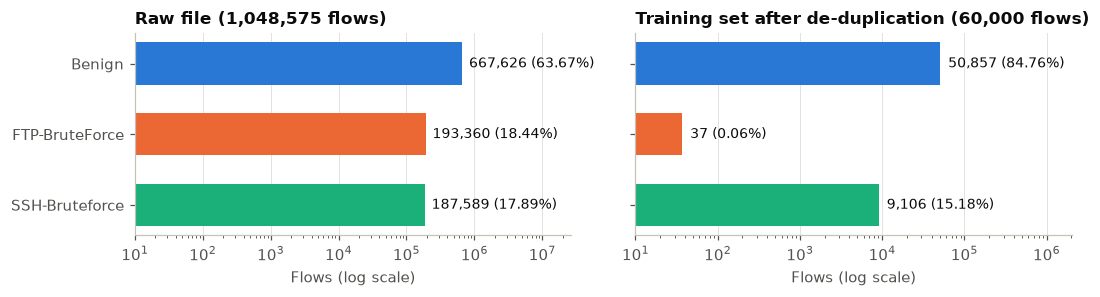

In [6]:
raw_counts = pd.Series(manifest["stage_counts"]["1. Raw file"]).drop("Total")
fig = plotting.plot_class_distribution(raw_counts, y_train.value_counts())
plotting.save_figure(fig, "2_3_1_class_distribution")

train_counts = eda.class_counts(y_train)
imbalance_ratio = train_counts.loc["Benign", "flows"] / train_counts.loc["FTP-BruteForce", "flows"]
print(f"Benign : FTP-BruteForce = {imbalance_ratio:,.0f} : 1")
train_counts.round(3)

### Univariate analysis (Q3)

Types, missing values, location, spread and shape (skewness, kurtosis) of six features, one per family of
CICFlowMeter statistics (Weeks 2–3 labs).

In [7]:
missing = eda.missing_values(X_train)
print(f"Missing values (isnull().sum()): {int(missing.sum())}")
display(X_train.dtypes.astype(str).value_counts().rename("columns").to_frame())

X_numeric = eda.numeric_model_features(X_train)
stats = eda.descriptive_statistics(X_numeric)
stats.round(4).to_csv(config.TABLES_DIR / "2_3_2_descriptive_statistics.csv")
right_skewed = int((stats["skewness"] > 1).sum())
print(f"{right_skewed} of {len(stats)} numeric features have skewness > 1")

family = ["Flow Duration", "Tot Fwd Pkts", "TotLen Fwd Pkts", "Flow Byts/s", "Fwd IAT Mean", "Init Fwd Win Byts"]
stats.loc[family].T.round(2)

Missing values (isnull().sum()): 0


,columns
float64,78
string,1


60 of 66 numeric features have skewness > 1


,Flow Duration,Tot Fwd Pkts,TotLen Fwd Pkts,Flow Byts/s,Fwd IAT Mean,Init Fwd Win Byts
mean,1.455457e+07,9.78,697.39,1.291744e+05,3.554549e+06,8.983790e+03
median,3.713140e+05,4.00,161.00,2.397310e+03,2.065850e+04,8.192000e+03
mode,1.000000e+00,1.00,0.00,0.000000e+00,0.000000e+00,8.192000e+03
std,3.332437e+07,60.02,1098.86,2.998637e+06,1.214392e+07,1.205479e+04
variance,1.110514e+15,3601.93,1207499.32,8.991826e+12,1.474748e+14,1.453179e+08
min,1.000000e+00,1.00,0.00,0.000000e+00,0.000000e+00,-1.000000e+00
max,1.199992e+08,4730.00,33327.00,3.940000e+08,1.199860e+08,6.553500e+04
range,1.199992e+08,4729.00,33327.00,3.940000e+08,1.199860e+08,6.553600e+04
IQR,4.020210e+06,9.00,1110.00,1.486319e+04,3.463788e+05,8.193000e+03
skewness,2.340000e+00,54.25,7.74,9.690000e+01,4.150000e+00,2.310000e+00


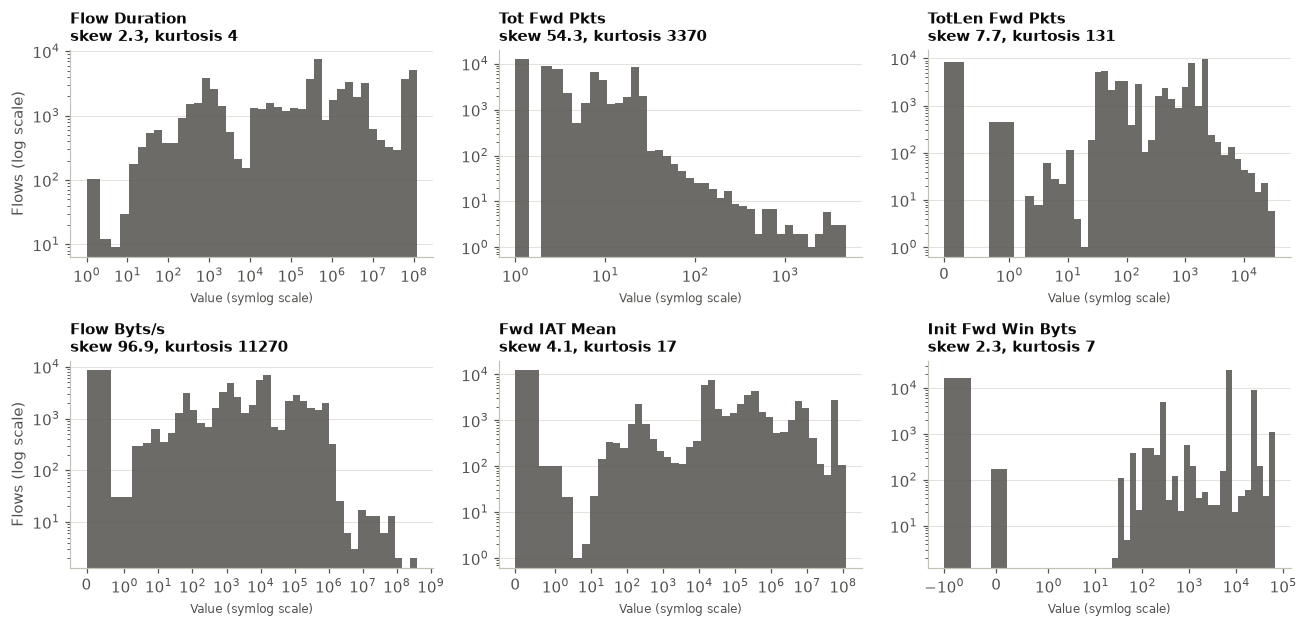

In [8]:
fig = plotting.plot_histograms(X_train, family, stats)
_ = plotting.save_figure(fig, "2_3_2_histograms")  # assigned, so the saved file path is not printed

### Correlation and redundancy (Q3)

Variances are ranked after the symmetric log `sign(x)·log1p(|x|)` (plain `log1p` fails on the `-1` window values).
The heatmap shows Pearson's r for the 20 highest-variance features (Week 5 lab).

Pkt Len Var == Pkt Len Std² on every training flow: True


,feature_a,feature_b,r
64,Idle Max,Idle Mean,1.0000
44,Idle Min,Idle Mean,0.9999
43,Idle Min,Idle Max,0.9998
295,Bwd IAT Tot,Bwd IAT Max,0.9979
211,Fwd IAT Tot,Fwd IAT Max,0.9954
275,Bwd IAT Mean,Bwd IAT Max,0.9948
274,Bwd IAT Mean,Bwd IAT Tot,0.9937
191,Fwd IAT Mean,Fwd IAT Max,0.9925
190,Fwd IAT Mean,Fwd IAT Tot,0.9858


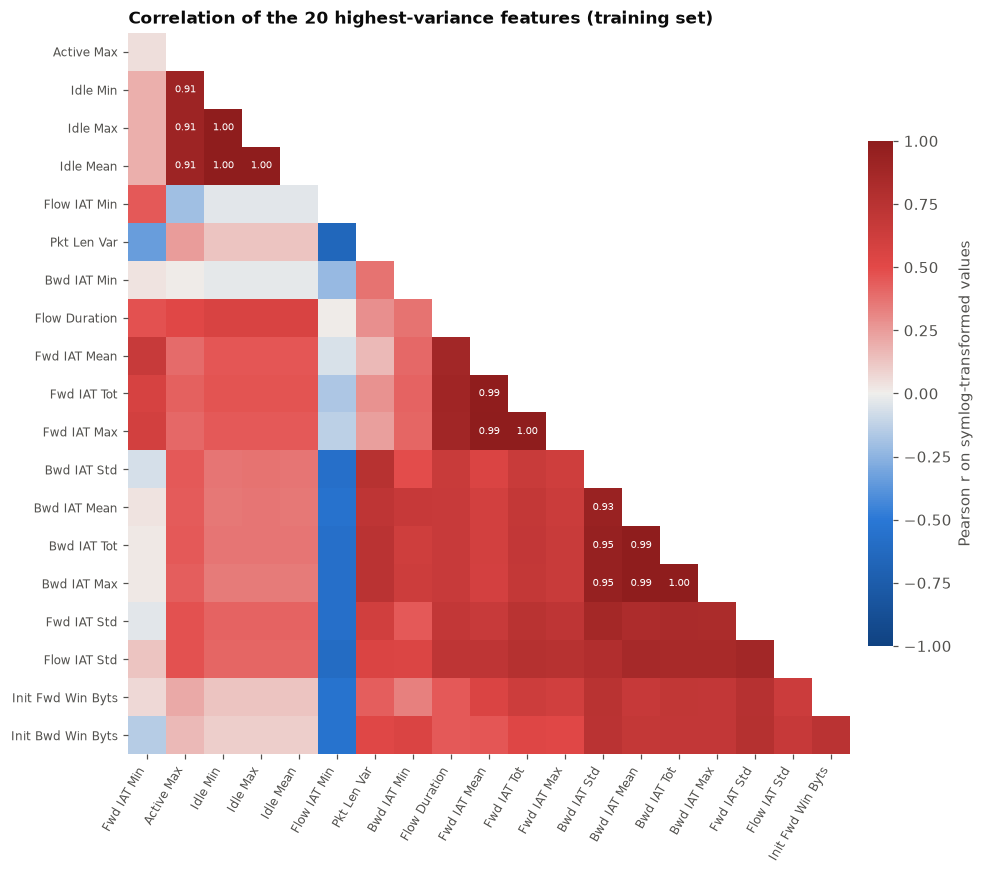

In [9]:
variance = eda.variance_ranking(X_numeric)
corr = eda.correlation_matrix(X_numeric, variance.head(20).index.tolist())
redundant = eda.highly_correlated_pairs(corr, threshold=0.95)
variance.head(20).round(2).rename("variance (symlog)").to_csv(config.TABLES_DIR / "2_3_3_variance_ranking.csv")
redundant.round(4).to_csv(config.TABLES_DIR / "2_3_3_redundant_pairs.csv", index=False)

fig = plotting.plot_correlation_heatmap(corr)
plotting.save_figure(fig, "2_3_3_correlation_heatmap")
pkt_var_is_std_squared = np.allclose(X_train["Pkt Len Var"], X_train["Pkt Len Std"] ** 2, rtol=1e-6)
print(f"Pkt Len Var == Pkt Len Std² on every training flow: {pkt_var_is_std_squared}")
redundant.round(4)

**Pearson or Spearman? (Week 5 lab, Exercise 3.)** Pearson measures linear association, Spearman any monotonic one. A
Spearman value well above Pearson points to a curved relationship that a log transform would straighten.

2,145 pairs; Spearman exceeds Pearson by > 0.3 for 749
Median gap |Spearman| - |Pearson|: raw 0.189, after symlog 0.009


,"Pearson, raw","Pearson, symlog",Spearman
threshold,,,
0.70,128,418,471
0.90,50,116,107
0.95,40,50,46


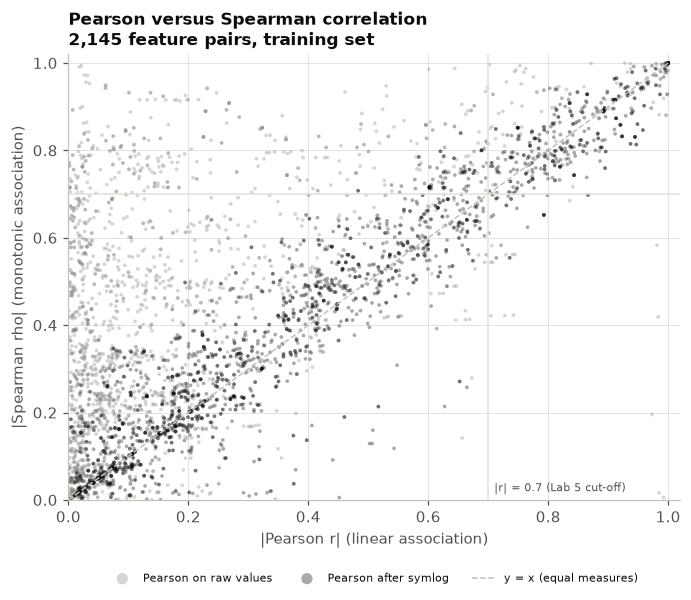

In [10]:
pairs = eda.pairwise_correlations(X_numeric)
method_counts = eda.correlation_method_counts(pairs)
method_counts.to_csv(config.TABLES_DIR / "2_3_3_correlation_methods.csv")
fig = plotting.plot_pearson_vs_spearman(pairs)
plotting.save_figure(fig, "2_3_3_pearson_vs_spearman")

gap_raw = pairs["spearman"].abs() - pairs["pearson_raw"].abs()
gap_symlog = pairs["spearman"].abs() - pairs["pearson_symlog"].abs()
curved_pairs = int((gap_raw > 0.3).sum())
c70 = method_counts.loc[0.7]  # pairs with |r| >= 0.7, the lab's cut-off
print(f"{len(pairs):,} pairs; Spearman exceeds Pearson by > 0.3 for {curved_pairs:,}")
print(f"Median gap |Spearman| - |Pearson|: raw {gap_raw.median():.3f}, after symlog {gap_symlog.median():.3f}")
method_counts.rename(columns={"pearson_raw": "Pearson, raw", "pearson_symlog": "Pearson, symlog",
                              "spearman": "Spearman"})

### Discriminative features and outliers (Q2, Q3)

Mutual information (MI) with the label, as a share of the label entropy H(Y), ranks the features; the box plots show
the six best-ranked features that are not strongly correlated (|r| < 0.9) with one already shown.

In [11]:
entropy = eda.label_entropy(y_train)
mi = eda.mutual_information_ranking(X_numeric, y_train)
mi_share = (mi / entropy * 100).rename("MI as % of H(Y)")
mi_share.round(2).to_csv(config.TABLES_DIR / "2_3_4_mutual_information.csv")
print(f"H(Y) = {entropy:.3f} nats; features with MI >= 90% of H(Y): {(mi_share >= 90).sum()} of {len(mi_share)}")
mi_share.head(15).round(1).to_frame()

H(Y) = 0.431 nats; features with MI >= 90% of H(Y): 26 of 66


,MI as % of H(Y)
Fwd Pkt Len Max,98.8
Init Bwd Win Byts,98.8
Bwd Pkt Len Max,98.7
Init Fwd Win Byts,98.6
Fwd Header Len,98.6
Bwd Seg Size Avg,98.4
Subflow Bwd Byts,98.4
Bwd Pkt Len Mean,98.3
Bwd Header Len,98.3
TotLen Bwd Pkts,98.3


Label,Benign,FTP-BruteForce,SSH-Bruteforce
Fwd Pkt Len Max,52.0,0.0,640.0
Init Bwd Win Byts,60.0,0.0,230.0
Bwd Pkt Len Max,147.0,0.0,976.0
Init Fwd Win Byts,8192.0,26883.0,26883.0
Fwd Header Len,72.0,40.0,712.0
Bwd Header Len,32.0,20.0,712.0


,Benign (% outliers),FTP-BruteForce (% outliers),SSH-Bruteforce (% outliers)
Fwd Pkt Len Max,1.2,0.0,0.2
Init Bwd Win Byts,22.7,0.0,0.0
Bwd Pkt Len Max,0.0,0.0,0.2
Init Fwd Win Byts,2.9,0.0,0.2
Fwd Header Len,3.7,0.0,6.3
Bwd Header Len,7.3,0.0,0.2


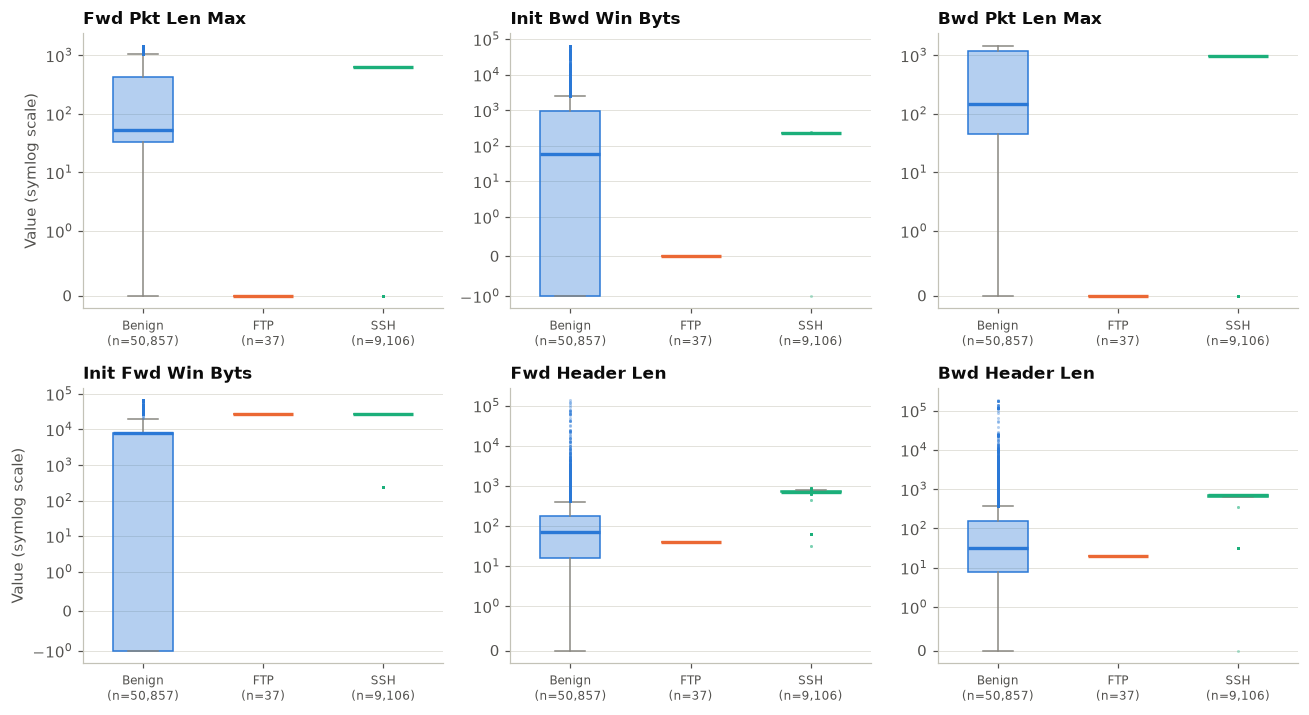

In [12]:
box_features = eda.select_diverse(mi, X_numeric, k=6, max_abs_r=0.9)
fig = plotting.plot_class_boxplots(X_numeric, y_train, box_features)
plotting.save_figure(fig, "2_3_4_boxplots_by_class")

medians = X_numeric[box_features].groupby(y_train, observed=True).median().T
outliers = eda.outlier_share(X_numeric, y_train, box_features)  # Tukey's 1.5 x IQR rule, per class
outliers.round(2).to_csv(config.TABLES_DIR / "2_3_4_outlier_share.csv")
display(medians)
outliers.round(1).add_suffix(" (% outliers)")

In [13]:
# Traits behind the near-perfect separation: the attackers' TCP window, uniform SSH flows, empty FTP flows.
window_share = X_train["Init Fwd Win Byts"].eq(26883).groupby(y_train, observed=True).mean() * 100
ssh = X_train[y_train == "SSH-Bruteforce"]
ssh_uniform = {c: ssh[c].eq(ssh[c].mode()[0]).mean() * 100 for c in ["Fwd Pkt Len Max", "Bwd Pkt Len Max"]}
ftp = X_train[y_train == "FTP-BruteForce"]
ftp_no_payload = (ftp["TotLen Fwd Pkts"].eq(0) & ftp["TotLen Bwd Pkts"].eq(0)).mean() * 100
print(f"Init Fwd Win Byts == 26,883 (% of class): {window_share.round(3).to_dict()}")
print(f"SSH flows at the modal value: {ssh_uniform}; FTP flows with no payload: {ftp_no_payload:.0f}%")

Init Fwd Win Byts == 26,883 (% of class): {'Benign': 0.065, 'FTP-BruteForce': 100.0, 'SSH-Bruteforce': 99.78}
SSH flows at the modal value: {'Fwd Pkt Len Max': np.float64(99.78036459477268), 'Bwd Pkt Len Max': np.float64(99.78036459477268)}; FTP flows with no payload: 100%


**Bivariate view:** the two highest-ranked non-redundant features together (Week 3 lab).

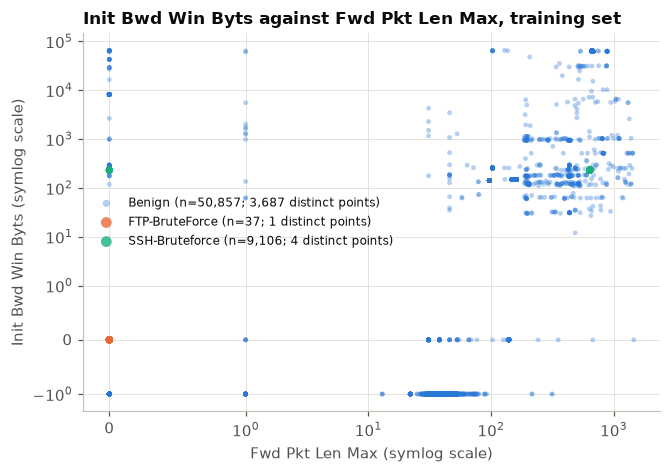

In [14]:
x_feature, y_feature = box_features[0], box_features[1]
fig = plotting.plot_scatter(X_train, y_train, x_feature, y_feature)
_ = plotting.save_figure(fig, "2_3_4_scatter")  # assigned, so the saved file path is not printed

**Mosaic plot (Week 5 lab, Exercise 2).** `Protocol` is nominal, so I compare it with the class by a mosaic plot:
column width = flows per protocol, tile height = class share.

Non-TCP flows (all benign): 16,356; benign share of TCP flows: 79.1%


Label,Benign,FTP-BruteForce,SSH-Bruteforce
Protocol,,,
0,1179,0,0
6,34501,37,9106
17,15177,0,0


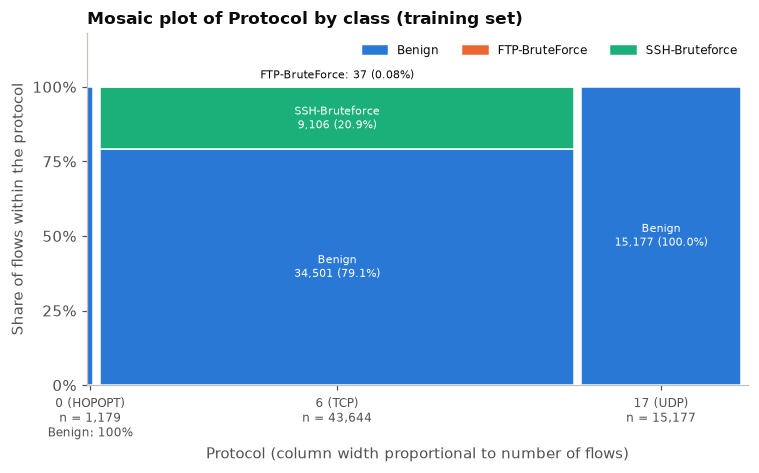

In [15]:
protocol_counts = pd.crosstab(X_train[config.PROTOCOL_COL].astype(int), y_train)
fig = plotting.plot_mosaic(protocol_counts)
plotting.save_figure(fig, "2_3_4_protocol_mosaic")

tcp_benign_share = protocol_counts.loc[6, "Benign"] / protocol_counts.loc[6].sum()
non_tcp = int(protocol_counts.drop(index=6).sum().sum())
print(f"Non-TCP flows (all benign): {non_tcp:,}; benign share of TCP flows: {tcp_benign_share:.1%}")
protocol_counts

**Pair plot (Week 6 lab).** A 2,000-flow subsample, as in the lab, but keeping every FTP flow so the rare class is
visible.

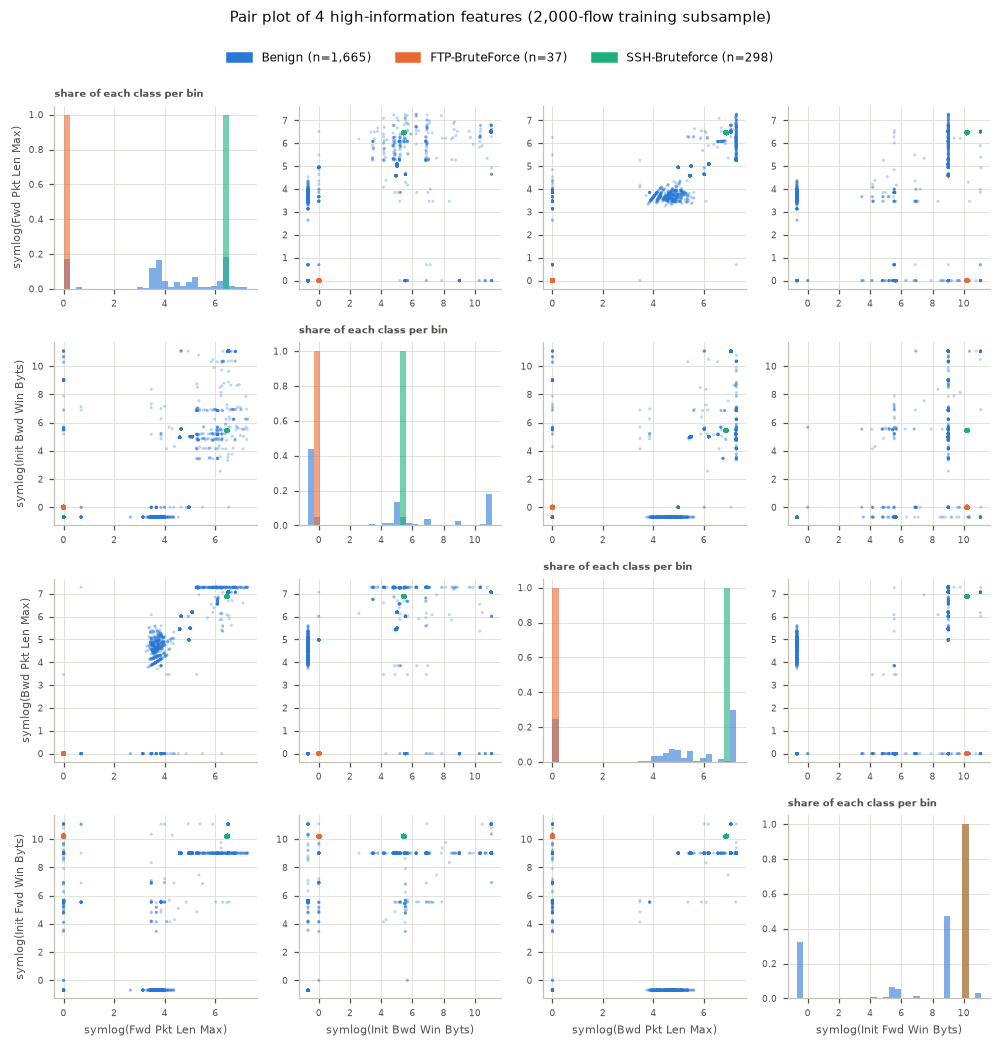

In [16]:
X_pair, y_pair = eda.stratified_subsample(X_train, y_train, n=2_000)
fig = plotting.plot_pair_matrix(X_pair, y_pair, box_features[:4])
_ = plotting.save_figure(fig, "2_3_4_pair_plot")  # assigned, so the saved file path is not printed

### Shortcut check: destination port (Q2)

CIC labelled flows partly by port, so `Dst Port` is a label proxy, not a property of the attack. This is why it is
excluded from the main model.

In [17]:
ports = eda.port_profile(X_train, y_train)
ports.round(3).to_csv(config.TABLES_DIR / "2_3_5_port_profile.csv", index=False)
benign_ports = X_train.loc[y_train == "Benign", config.DST_PORT_COL]
benign_on_21, benign_on_22 = benign_ports.eq(21).mean() * 100, benign_ports.eq(22).mean() * 100
print(f"Benign flows on port 21: {benign_on_21:.3f}%, on port 22: {benign_on_22:.3f}%")
ports.round(3)

Benign flows on port 21: 0.006%, on port 22: 0.079%


,class,dst_port,percent_of_class,distinct_ports_in_class
0,Benign,53,28.368,2544
1,Benign,80,18.731,2544
2,Benign,3389,17.012,2544
3,FTP-BruteForce,21,100.000,1
4,SSH-Bruteforce,22,100.000,1


## 2.4 EDA conclusions

The decisions each finding leads to (details and discussion in report section 2.4).

In [18]:
conclusions = pd.DataFrame([
    ("Q1", f"FTP is {train_counts.loc['FTP-BruteForce', 'percent']:.2f}% of training flows",
     "macro F1 and per-class recall; SMOTE capped, inside the folds"),
    ("Q2", f"{(mi_share >= 90).sum()} of {len(mi_share)} features carry >= 90% of H(Y)",
     "near-perfect scores are expected; test shortcuts instead"),
    ("Q2", f"TCP window 26,883 on {window_share['FTP-BruteForce']:.0f}% of FTP, "
           f"{window_share['Benign']:.3f}% of benign flows", "ablation without the attackers' TCP settings"),
    ("Q2", "Dst Port is a label proxy", "excluded; tested in an ablation"),
    ("Q3", f"{right_skewed} skewed features; {c70['spearman']} pairs with Spearman |rho| >= 0.7",
     "symlog option, scaling, correlation-based feature selection"),
], columns=["question", "finding", "decision"])
conclusions

,question,finding,decision
0,Q1,FTP is 0.06% of training flows,"macro F1 and per-class recall; SMOTE capped, i..."
1,Q2,26 of 66 features carry >= 90% of H(Y),near-perfect scores are expected; test shortcu...
2,Q2,"TCP window 26,883 on 100% of FTP, 0.065% of be...",ablation without the attackers' TCP settings
3,Q2,Dst Port is a label proxy,excluded; tested in an ablation
4,Q3,60 skewed features; 471 pairs with Spearman |r...,"symlog option, scaling, correlation-based feat..."


## **Save the numbers quoted in the report** (`reports/numbers.json`)

In [19]:
def port_share(cls: str) -> float:
    return ports.loc[ports["class"] == cls, "percent_of_class"].iloc[0]

pct = train_counts["percent"]
report_numbers.record(
    train_rows=f"{len(y_train):,}", test_rows=f"{len(y_test):,}",
    train_benign=f"{(y_train == 'Benign').sum():,}", train_ftp=f"{(y_train == 'FTP-BruteForce').sum()}",
    train_ssh=f"{(y_train == 'SSH-Bruteforce').sum():,}",
    test_benign=f"{(y_test == 'Benign').sum():,}", test_ftp=f"{(y_test == 'FTP-BruteForce').sum()}",
    test_ssh=f"{(y_test == 'SSH-Bruteforce').sum():,}",
    train_ftp_pct=f"{pct['FTP-BruteForce']:.2f}%", train_benign_pct=f"{pct['Benign']:.2f}%",
    train_ssh_pct=f"{pct['SSH-Bruteforce']:.2f}%", imbalance_ratio=f"{imbalance_ratio:,.0f}",
    numeric_features=f"{X_numeric.shape[1]}", skewed_features=f"{right_skewed}",
    corr_pairs=f"{len(pairs):,}", corr_pearson_raw_07=f"{c70['pearson_raw']}",
    corr_pearson_symlog_07=f"{c70['pearson_symlog']}", corr_spearman_07=f"{c70['spearman']}",
    corr_curved_pairs=f"{curved_pairs:,}", corr_gap_raw=f"{gap_raw.median():.3f}",
    corr_gap_symlog=f"{gap_symlog.median():.3f}",
    redundant_pairs_095=f"{len(redundant)}", heatmap_pairs=f"{len(corr) * (len(corr) - 1) // 2}",
    mi_entropy=f"{entropy:.3f}", mi_high_features=f"{(mi_share >= 90).sum()}", mi_top_feature=mi_share.index[0],
    mi_top_share=f"{mi_share.iloc[0]:.1f}%",
    ftp_no_payload=f"{ftp_no_payload:.0f}%", ssh_modal_fwd_len=f"{ssh_uniform['Fwd Pkt Len Max']:.1f}%",
    window_ftp=f"{window_share['FTP-BruteForce']:.0f}%", window_ssh=f"{window_share['SSH-Bruteforce']:.2f}%",
    window_benign=f"{window_share['Benign']:.3f}%",
    port_ftp_21=f"{port_share('FTP-BruteForce'):.0f}%", port_ssh_22=f"{port_share('SSH-Bruteforce'):.0f}%",
    benign_port_21=f"{benign_on_21:.3f}%", benign_port_22=f"{benign_on_22:.3f}%",
    protocol_non_tcp=f"{non_tcp:,}", protocol_tcp_benign_share=f"{tcp_benign_share:.0%}",
    outlier_benign_max=f"{outliers['Benign'].max():.1f}%",
)

{'train_rows': '60,000',
 'test_rows': '15,000',
 'train_benign': '50,857',
 'train_ftp': '37',
 'train_ssh': '9,106',
 'test_benign': '12,715',
 'test_ftp': '9',
 'test_ssh': '2,276',
 'train_ftp_pct': '0.06%',
 'train_benign_pct': '84.76%',
 'train_ssh_pct': '15.18%',
 'imbalance_ratio': '1,375',
 'numeric_features': '66',
 'skewed_features': '60',
 'corr_pairs': '2,145',
 'corr_pearson_raw_07': '128',
 'corr_pearson_symlog_07': '418',
 'corr_spearman_07': '471',
 'corr_curved_pairs': '749',
 'corr_gap_raw': '0.189',
 'corr_gap_symlog': '0.009',
 'redundant_pairs_095': '9',
 'heatmap_pairs': '190',
 'mi_entropy': '0.431',
 'mi_high_features': '26',
 'mi_top_feature': 'Fwd Pkt Len Max',
 'mi_top_share': '98.8%',
 'ftp_no_payload': '100%',
 'ssh_modal_fwd_len': '99.8%',
 'window_ftp': '100%',
 'window_ssh': '99.78%',
 'window_benign': '0.065%',
 'port_ftp_21': '100%',
 'port_ssh_22': '100%',
 'benign_port_21': '0.006%',
 'benign_port_22': '0.079%',
 'protocol_non_tcp': '16,356',
 'prot